# COMP47670 Assignment 1 - Autumn 2026/27
## Task 3: Data Analysis

**Student Name**: Ellen Lyons

**Student Number**: 26117753

In [1]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# when I make a lot of plots I usually use the same settings for all 
plt.rcParams.update({
    "figure.figsize": (8, 4.5),   
    "axes.titlesize": 14,         
    "axes.labelsize": 13,        
    "xtick.labelsize": 11,        
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.grid": True,           
})

### Load data
**Issue**: *Year Built* was loading with decimal places even though I got rid of them in Task 2. 

**Solution**: I read the pandas documentation for ``pd.read_csv`` and it has an argument to specify the ``dtype``, so I just re-specified the format I want.

In [2]:
# load in the ABT from task 2
df = pd.read_csv(
    "ABT.csv",
    index_col=0, # already assigned 'property index' as this
    parse_dates=["Date Sold"],
    dtype={"Year Built": "Int64"}
)

df.head()

,Year Built,Location,Date Sold,Sale Price (EUR),Garden,Size (sq ft),First Time Buyer,Garage,House Type,Number of Storeys,Number of Bedrooms,Number of Bathrooms
Property Reference,,,,,,,,,,,,
PROP-105204,1984,Oak Park,2022-12-26,359086,Yes,1131,Yes,Yes,Detached,1.5,3,1
PROP-105203,2019,Porter Square,2022-12-25,734419,Yes,1941,No,Yes,Detached,2.0,3,2
PROP-105202,2021,Porter Square,2022-12-19,724835,Yes,1996,No,Yes,Detached,2.0,3,2
PROP-105201,2013,Avoca,2022-12-18,446404,Yes,1463,No,Yes,Detached,1.5,3,2
PROP-105200,2008,Brookville,2022-12-17,554762,Yes,1660,No,Yes,Detached,2.0,3,2


In [3]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Year Built,1392.0,1981.265086,1885.0,1963.0,1979.0,2013.0,2022.0,31.766731
Date Sold,1450,2024-02-18 08:22:30.620689,2022-01-15 00:00:00,2023-04-11 00:00:00,2024-05-11 00:00:00,2025-04-09 00:00:00,2025-12-28 00:00:00,NaN
Sale Price (EUR),1450.0,434333.88069,91929.0,322901.75,388854.5,508703.75,1632196.0,176370.546146
Size (sq ft),1450.0,1422.711034,294.0,1058.25,1398.5,1701.0,3706.0,443.761325
Number of Storeys,1450.0,1.335172,1.0,1.0,1.0,2.0,2.0,0.453577
Number of Bedrooms,1450.0,2.883448,1.0,2.0,3.0,3.0,5.0,0.730534
Number of Bathrooms,1450.0,1.529655,1.0,1.0,2.0,2.0,3.0,0.546792


**Problem:** How do I display all of this data?

**Solution:**

For the numerical features, I went for a simple histogram to show the distribution. This was discussed in the Week07 notebooks/lab and is straightforward to implement. Some other plots are obvious to me, for example I want to see how price is related to various other features, so I will use scatter plots for that. For the categorical features, it is useful to use bar charts. Examples of code for these plots are also in the lectures, and again, they are easy to do. 

I know that real estate agents often use metrics like 'price per sq ft', so I will try to recreate that here. Line plots can be used for seeing time-relationships.

For some more interesting plots, I searched around the internet for property sale analysis examples. I found a data scientist who had looked at some property sales in Dublin (https://niallmartin.io/posts/data-analysis-dublin-property-trends/). I looked at the Daft.ie reports (https://www.daft.ie/report/sales/daft-ie-sales-report-2026q3.pdf). While the data I am working with is a lot simpler, and doesn't exactly match up with fancy technical reports, it gave me some inspiration. I have used ``seaborn``a little bit in past projects, so I will use it a bit more here, too. 

### Exploring individual features
Before I make comparison or look at correlations between variables, I am going to have a look at features individually. This way, I can spot any outliers, like discussed at the end of Task 2, and to decide what things to look at in more detail.

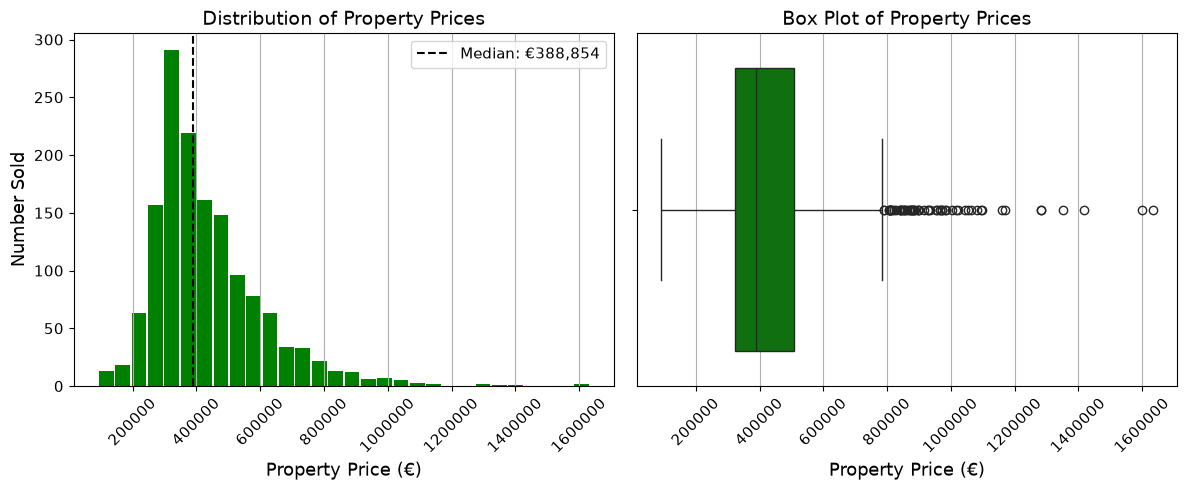

In [4]:
# subplots to focus on sale prices
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

# histogram of sale price
ax[0] = df["Sale Price (EUR)"].hist(
    ax=ax[0],
    bins=30,
    color="green",
    rwidth=0.9,
    grid=False
)
ax[0].axvline(x = df["Sale Price (EUR)"].median(), color = "black", linestyle="--", label=f"Median: €{df["Sale Price (EUR)"].median():,.0f}")
ax[0].ticklabel_format(axis="x", style = "plain")
ax[0].set_ylabel("Number Sold")
ax[0].set_xlabel("Property Price (€)")
ax[0].set_title("Distribution of Property Prices")
ax[0].tick_params(axis='x', rotation=45)
ax[0].xaxis.grid(True)
ax[0].legend()

# box plot to see distribution
sns.boxplot(x=df["Sale Price (EUR)"], color="green")
ax[1].ticklabel_format(axis="x", style = "plain")
ax[1].tick_params(axis="x", rotation=45)
ax[1].set_xlabel("Property Price (€)")
ax[1].xaxis.grid(True)
ax[1].set_title("Box Plot of Property Prices")

plt.tight_layout()
plt.show()

In [5]:
q1, q3 = df["Sale Price (EUR)"].quantile([0.25, 0.75])
IQR = q3 - q1
upper = q3 + 1.5 * IQR
print((df["Sale Price (EUR)"] > upper).sum(), "high outliers")

62 high outliers


**Property Price Analysis:**
- We can see from the histogram that house prices are skewed to the right, which I would expect as it is rare for properties to sell for really high values.
- Most properties sold for €300,000 to €500,000. 
- The median price was €388,854 which I plotted on the histogram, too.
- Real estate agents tend to use median prices instead of average, because the high € values would skew an average. 

- As discussed, I was looking for interesting plots to use.
- After browsing the ``seaborn`` documentation/gallery, I chose a box plot to accompany the histogram.
- The box shows the quartiles of the dataset, and the "whiskers" show the rest of the distribution, except for points that are outliers  (https://seaborn.pydata.org/generated/seaborn.boxplot.html#seaborn.boxplot).
- So the box is showing the middle 50% of the sales, and the black line in the box is the median.
- The circles outside the whiskers are the outliers; we can see that only high prices are outliers, there are no unusually cheap properties sold.
- The cheapest sale was €91929, which I found in using the ``df.describe()`` function earlier.
- I did a quick IQR calculation in the cell below the plots, which tells me there are 62 outliers in the high range.
- I don't have any reason to believe any of the outliers are "incorrect" data, as all the values seem reasonable, so I kept them all.  


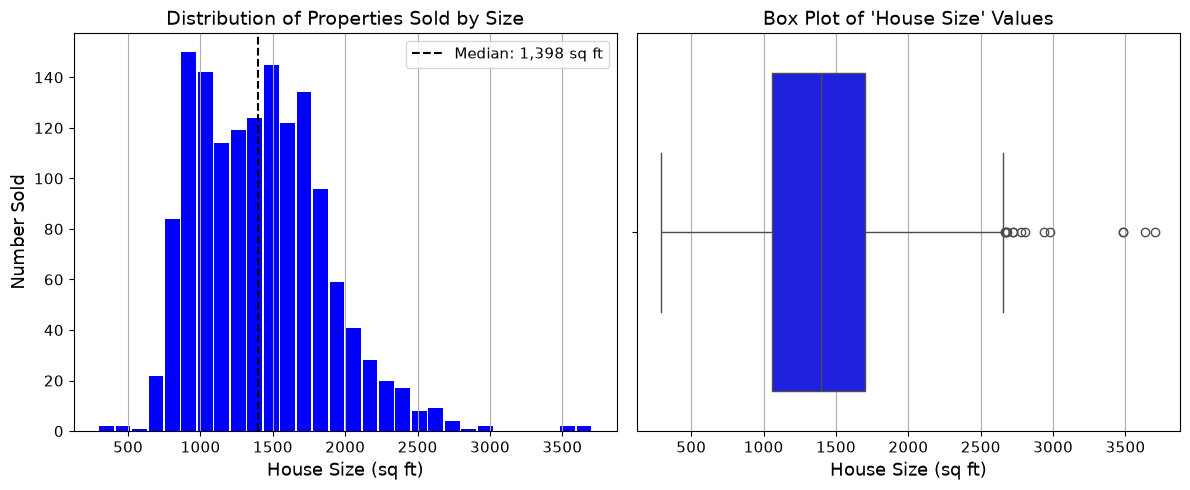

In [6]:
# subplots to focus on house size
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

# histogram of sale price
ax[0] = df["Size (sq ft)"].hist(
    ax=ax[0],
    bins=30,
    color="blue",
    rwidth=0.9,
    grid=False
)
ax[0].axvline(x = df["Size (sq ft)"].median(), color = "black", linestyle="--", label=f"Median: {df["Size (sq ft)"].median():,.0f} sq ft")
ax[0].ticklabel_format(axis="x", style = "plain")
ax[0].set_ylabel("Number Sold")
ax[0].set_xlabel("House Size (sq ft)")
ax[0].set_title("Distribution of Properties Sold by Size")
#ax[0].tick_params(axis='x', rotation=45)
ax[0].xaxis.grid(True)
ax[0].legend()

# box plot to see distribution
sns.boxplot(x=df["Size (sq ft)"], ax=ax[1], color="blue")
ax[1].ticklabel_format(axis="x", style = "plain")
#ax[1].tick_params(axis="x", rotation=45)
ax[1].set_xlabel("House Size (sq ft)")
ax[1].xaxis.grid(True)
ax[1].set_title("Box Plot of 'House Size' Values")

plt.tight_layout()
plt.show()

In [7]:
q1, q3 = df["Size (sq ft)"].quantile([0.25, 0.75])
IQR = q3 - q1
lower = q1 - 1.5 * IQR
upper = q3 + 1.5 * IQR
print((df["Size (sq ft)"] < lower).sum(), "low outliers")
print((df["Size (sq ft)"] > upper).sum(), "high outliers")

0 low outliers
14 high outliers


**Property Size Analysis:**
- I did the same plots for the feature *Size (sq ft)*.
- The median value is 1,398 sq ft.
- Most houses were between 1000 to 1750 sq ft.
- There are no low outliers according to my IQR calculation; in Task 2 I was wondering whether the smallest house size was a data error, but now it seems it is a genuine value.
- There are some outliers on the higher side, but none are totally unrealistic values.

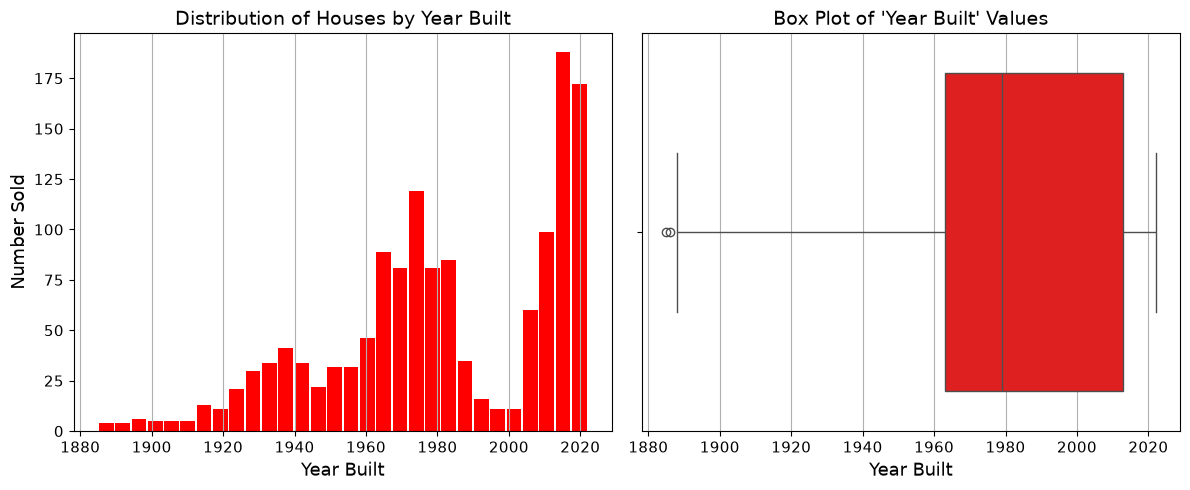

In [8]:
# subplots to focus on year built
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

# histogram of sale price
df["Year Built"].hist(
    ax=ax[0],
    bins=30,
    color="red",
    rwidth=0.9,
    grid=False
)
ax[0].ticklabel_format(axis="x", style = "plain")
ax[0].set_ylabel("Number Sold")
ax[0].set_xlabel("Year Built")
ax[0].set_title("Distribution of Houses by Year Built")
#ax[0].tick_params(axis='x', rotation=45)
ax[0].xaxis.grid(True)

# box plot to see distribution
sns.boxplot(x=df["Year Built"], color="red")
ax[1].ticklabel_format(axis="x", style = "plain")
#ax[1].tick_params(axis="x", rotation=45)
ax[1].set_xlabel("Year Built")
ax[1].xaxis.grid(True)
ax[1].set_title("Box Plot of 'Year Built' Values")

plt.tight_layout()
plt.show()

**Year Built Analysis:**
- The distribution is skewed to the left; I expected most builds to be new, so this makes sense.
- I did not take a median value because we are dealing with years so that makes no sense.
- The box plot shows some outliers on the lower side, that's ok with me as it is not unusual to have one or two really old properties on the market.
- There are no outliers on the high side; this data only goes up to 2020.

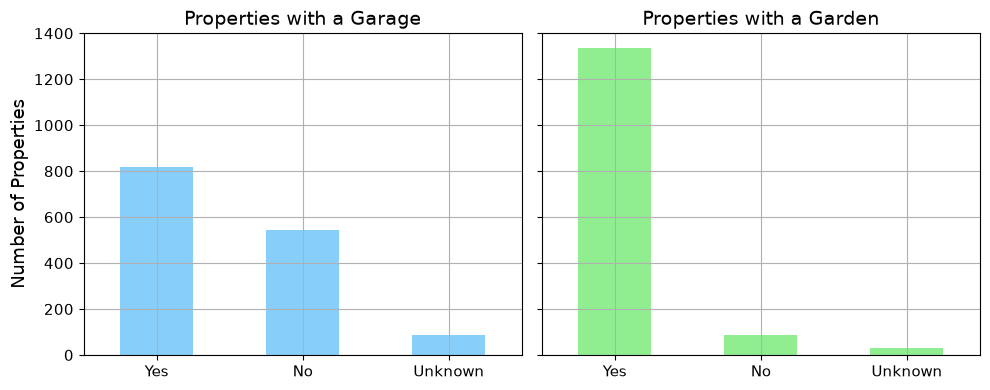

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# garage
df["Garage"].value_counts().plot(kind="bar", ax=ax[0], color="lightskyblue")
ax[0].set_title("Properties with a Garage")
ax[0].set_xlabel("")
ax[0].set_ylabel("Number of Properties")
ax[0].tick_params(axis="x", rotation=0)

# garden
df["Garden"].value_counts().plot(kind="bar", ax=ax[1], color="lightgreen")
ax[1].set_title("Properties with a Garden")
ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Garden/Garage Analysis:**
- The majority of properties sold had a garden, so I probably won't look further into any trends involving gardens.
- Garage distribution is more interesting, perhaps proeprties with a garage sold for more?

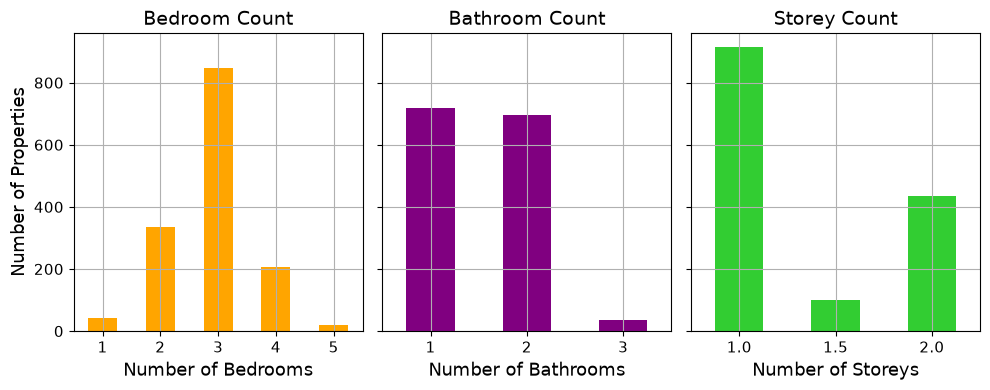

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4), sharey=True)

# bedrooms
df["Number of Bedrooms"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="orange")
ax[0].set_title("Bedroom Count")
ax[0].set_xlabel("Number of Bedrooms")
ax[0].set_ylabel("Number of Properties")
ax[0].tick_params(axis="x", rotation=0)

# bathrooms
df["Number of Bathrooms"].value_counts().sort_index().plot(kind="bar", ax=ax[1], color="purple")
ax[1].set_title("Bathroom Count")
ax[1].set_xlabel("Number of Bathrooms")
ax[1].tick_params(axis="x", rotation=0)

# storey
df["Number of Storeys"].value_counts().sort_index().plot(kind="bar", ax=ax[2], color="limegreen")
ax[2].set_title("Storey Count")
ax[2].set_xlabel("Number of Storeys")
ax[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Bedroom/Bathroom/Storey Count Analysis:**
- Most properties have 3 bedrooms.
- There are almost equal amounts of properties with 1 bathroom as there are with 2 bathrooms.
- Given this, I probably won't look at further trends involving the number of bathrooms.
- I am a bit confused as to why 1-storey houses dominate? This is not what I expected, I thought 2-storey houses would be most common.

Below I am printing the ``value_counts()`` of the *House Type*s with 1 storey.

In [11]:
# of the 1-storey houses, what types are they
mask = df["Number of Storeys"] == 1.0
df.loc[mask, "House Type"].value_counts()

House Type
Detached          650
Bungalow          157
Semi-Detached      47
Duplex             28
Terraced           24
End-of-Terrace      8
Name: count, dtype: int64

In my opinion, a detached single-story house *is* a bungalow? Also a duplex cannot be 1 storey, by definition? Seems to be an issue with this data, so I won't explore any trends related to the *Number of Storeys*.

### Relationships with Price €€€

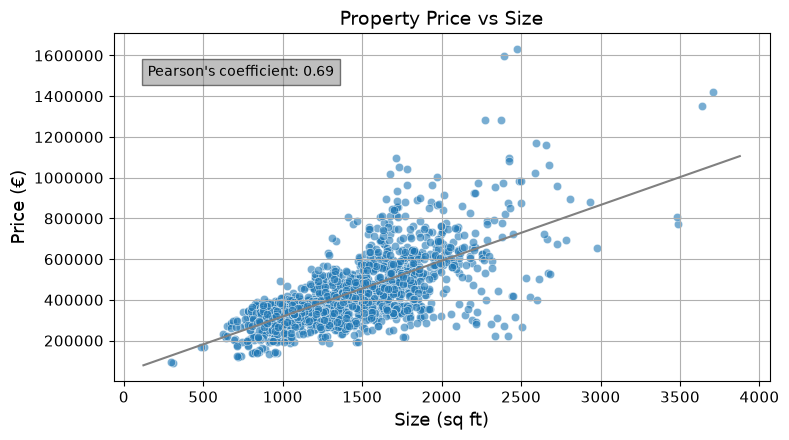

In [12]:
import scipy as sp

# ----- took this snippet about pearson correlation from here ----
# Source - https://stackoverflow.com/a/73199227
# Posted by Leon Shpaner, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-28, License - CC BY-SA 4.0

# call the scipy function for pearson correlation
r, p = sp.stats.pearsonr(x=df["Size (sq ft)"], y=df["Sale Price (EUR)"])
ax = plt.gca() # Get a matplotlib's axes instance

# price v size
ax = sns.scatterplot(data=df, x="Size (sq ft)", y="Sale Price (EUR)", alpha=0.6)

# The following code block adds the correlation line:
m, b = np.polyfit(df["Size (sq ft)"], df["Sale Price (EUR)"], 1)
X_plot = np.linspace(ax.get_xlim()[0],ax.get_xlim()[1],100)
plt.plot(X_plot, m*X_plot + b, "-", color = "grey")

ax.set_ylabel("Price (€)")
ax.set_xlabel("Size (sq ft)")
ax.set_title("Property Price vs Size")
ax.ticklabel_format(axis="y", style = "plain")
ax.text(150, 1500000, f"Pearson's coefficient: {r:.2f}", bbox=dict(facecolor="grey", alpha=0.5))
plt.tight_layout()
plt.show()

**Size vs Price Analysis:**
- This is a very informative plot: the price of a property increases with the size.
- I expected this, it is intuitive that in general, the bigger a property is, the more money it will be sold for.
- A linear regression through the datapoints would give us the price per square foot.
- I calculated the Pearson coefficient to be 0.69, which indicates a positive linear relationship between the two variables.


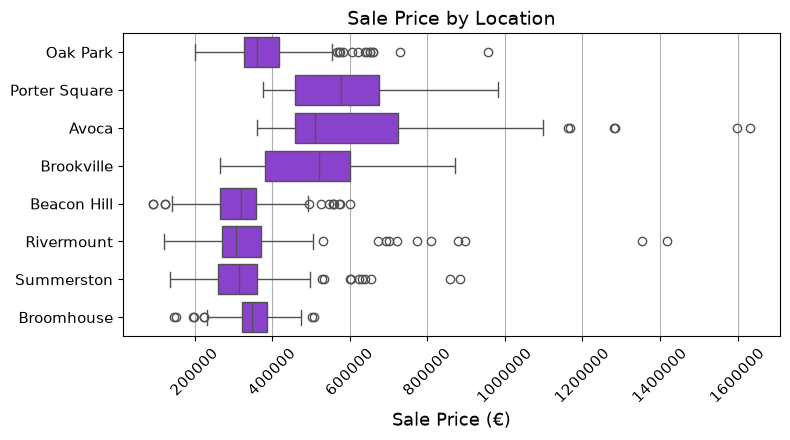

In [13]:
ax = sns.boxplot(data=df, x="Sale Price (EUR)", y="Location", color="blueviolet")
ax.set_xlabel("Sale Price (€)")
ax.set_ylabel("")
ax.set_title("Sale Price by Location")
ax.ticklabel_format(axis="x", style = "plain")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [14]:
medians = df.groupby(["Location"])["Sale Price (EUR)"].median()
medians.sort_values(ascending=False)

Location
Porter Square    578025.0
Brookville       521639.0
Avoca            511445.0
Oak Park         361809.0
Broomhouse       347516.0
Beacon Hill      319029.0
Summerston       313942.5
Rivermount       305640.5
Name: Sale Price (EUR), dtype: float64

**Price vs Location Analysis:**
- I opted for another box plot here to show the distribution of price for each location.
- The box plot above shows us that the highest prices occur in Avoca.
- Avoca has the highest outlier prices, as indicated by the circles plotted outside of the whiskers.
- Porter Square has the highest median price.
- The median for Avoca is also skewed to the right.
- The lowest outlier price is at Beacon Hill, but Rivermount, Summerston all have similarly low sale prices to one another.
- Broomhouse has a few outliers that are low in price, too.

### Trends Over Time

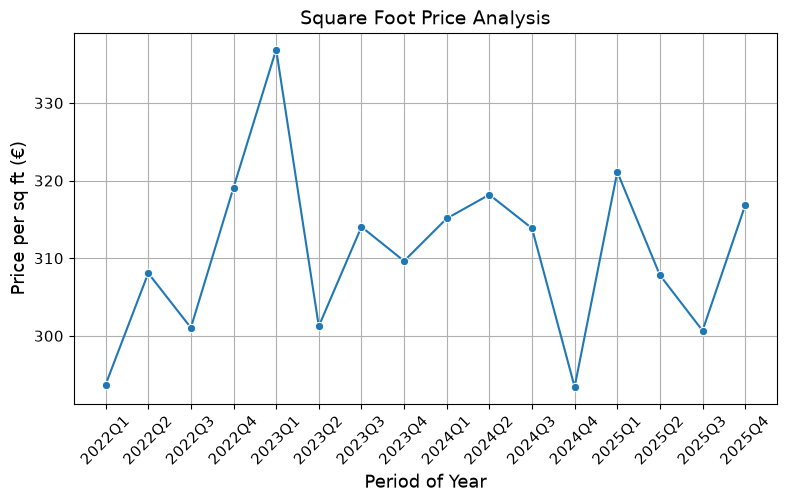

In [15]:
df["price_per_sq_ft"] = df["Sale Price (EUR)"] / df["Size (sq ft)"]
df = df.sort_values("Date Sold")
df["quarter"] = df["Date Sold"].dt.to_period("Q").astype(str) # got this code from datascientyst.com/convert-datetime-to-quarter-in-pandas/


ax = sns.lineplot(data=df, x="quarter", y="price_per_sq_ft",
             estimator="median", errorbar=None, marker="o")
ax.set_ylabel("Price per sq ft (€)")
ax.set_xlabel("Period of Year")
plt.tight_layout()
ax.tick_params(axis='x', rotation=45)
ax.set_title("Square Foot Price Analysis")
plt.show()


**Price per Sq Ft Analysis:**
- The plot shows the price per sq ft as a function of time, with time split into quarters per year.
- The data spans from 2022 to 2025.
- There is no observed trend.

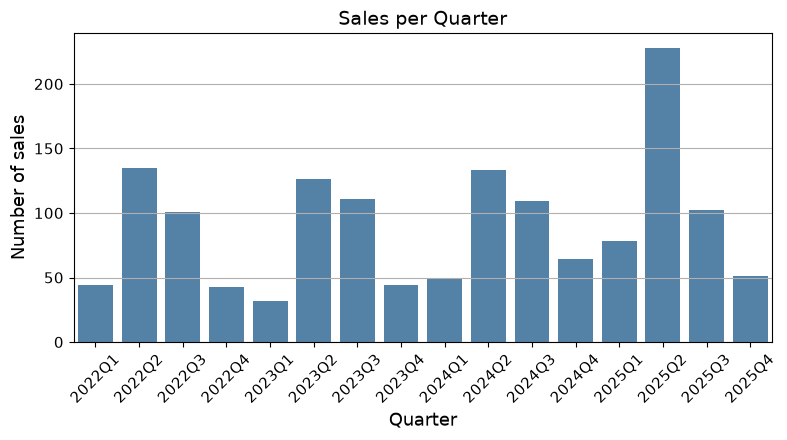

In [16]:
# sales per quarter
ax = sns.countplot(data=df, x="quarter", color="steelblue")
ax.set_xlabel("Quarter")
ax.set_ylabel("Number of sales")
ax.tick_params(axis="x", rotation=45)
ax.set_title("Sales per Quarter")
plt.tight_layout()
plt.show()

**Sales per Quarter Analysis:**
- I used a ``countplot`` here: https://seaborn.pydata.org/generated/seaborn.countplot.html
- "A count plot can be thought of as a histogram across a categorical, instead of quantitative, variable."
- In each year, Q2 is the busiest time for property sales ie the most sales are made in Q2.
- Q1 and Q4 consistently have the lowest amount of sales.
- There was a surge in sales in Q2 in 2025!

### Other Trends

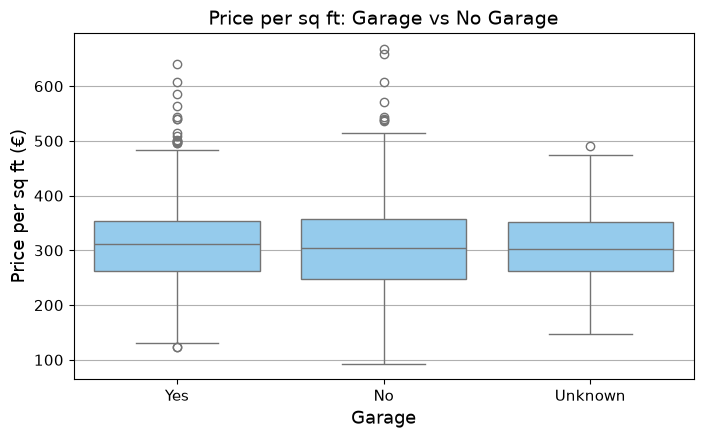

In [17]:
ax = sns.boxplot(data=df, x="Garage", y="price_per_sq_ft", color="lightskyblue")
ax.set_ylabel("Price per sq ft (€)")
ax.set_title("Price per sq ft: Garage vs No Garage")
plt.show()

**Price per Sq Ft with and without a Garage:**
- Based on the boxplot, the distribution of data is very similar for properties with and without a garage.
- However, the median price per square foot is slightly higher for those with a garage.

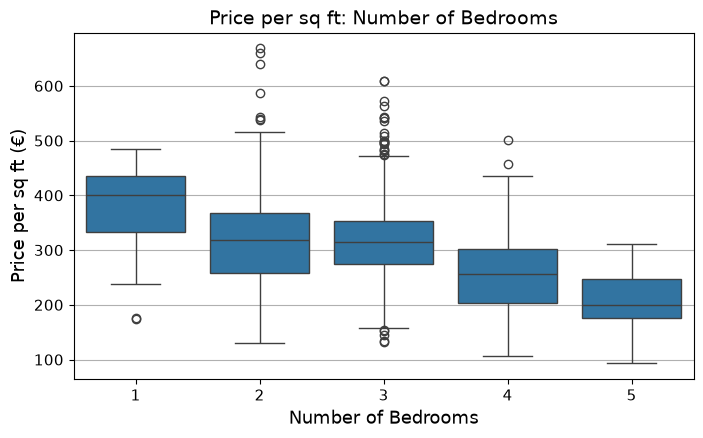

In [18]:
ax = sns.boxplot(data=df, x="Number of Bedrooms", y="price_per_sq_ft")
ax.set_ylabel("Price per sq ft (€)")
ax.set_title("Price per sq ft: Number of Bedrooms")
plt.show()

**Price per sq ft vs Number of Bedrooms Analysis:**
- This is an interesting result: the median price per sq ft is lower for properties with more bedrooms.
- I would like to see the location of the properties with 5 bedrooms, so I used a simple mask in the cell below.

In [19]:
# of the 4+ bedroom houses, where are they located
mask = df["Number of Bedrooms"] >= 4
percentage = ((df.loc[mask, "Location"].value_counts()/df["Location"].value_counts()) * 100).sort_values(ascending=False)
print(f"Percentage of properties with 4+ rooms by location: {percentage}")

Percentage of properties with 4+ rooms by location: Location
Rivermount       25.543478
Summerston       23.456790
Oak Park         16.943522
Avoca            15.695067
Broomhouse       12.977099
Beacon Hill      10.679612
Brookville        8.979592
Porter Square     6.930693
Name: count, dtype: float64


In [20]:
# of the 1 bedroom houses, where are they located
mask = df["Number of Bedrooms"] == 1
percentage = ((df.loc[mask, "Location"].value_counts()/df["Location"].value_counts()) * 100).sort_values(ascending=False)
print(f"Percentage of properties with 1 room by location: {percentage}")

Percentage of properties with 1 room by location: Location
Brookville       8.979592
Beacon Hill      6.796117
Porter Square    1.980198
Avoca            1.793722
Summerston       1.234568
Rivermount       1.086957
Oak Park         0.996678
Broomhouse            NaN
Name: count, dtype: float64


- The two locations with the highest % of properties with 4 bedrooms or more are also the two locations with the lowest median sale price!
- The most expensive location, Porter Square, has the lowest % share of properties with 4+ bedrooms.
- This tells us that location is more important to a property's value than the number of bedrooms.

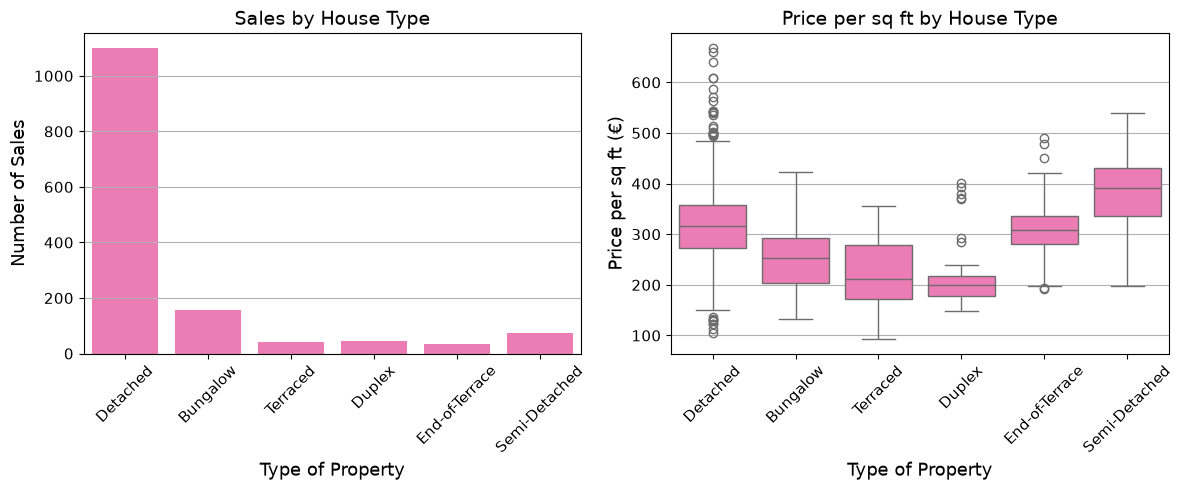

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

# sales by type
ax[0] = sns.countplot(data=df, x="House Type", color="hotpink", ax=ax[0])
ax[0].set_xlabel("Type of Property")
ax[0].set_ylabel("Number of Sales")
ax[0].tick_params(axis="x", rotation=45)
ax[0].set_title("Sales by House Type")

# price per sq ft per type
sns.boxplot(data=df, x="House Type", y="price_per_sq_ft",
            color="hotpink", ax=ax[1])
ax[1].set_xlabel("Type of Property")
ax[1].set_ylabel("Price per sq ft (€)")
ax[1].set_title("Price per sq ft by House Type")
ax[1].tick_params(axis="x", rotation=45)


plt.tight_layout()
plt.show()

**Property Type Analysis:**
- Detached houses are by far the most commonly sold type of property.
- The biggest outliers in price per square foot are in the detached house category; this could be because the highest valued houses are detached, but also the majority of the dataset is of detached houses.
- But interestingly, the semi-detached houses have the highest median value - look at the black line within the box in the box plot.
- Semi-detached houses are worth more per sq ft than the rest of the property types (but also this is based off less than 100 sales, so the sample size is small).

**Important Caveat**:
Note that, from earlier, that it is likely the 'Detached' category has a misleading number of properties (see discussion of 'Number of Stories').

### Key Insight Summary
- Median property price is approximately €389,000, and median size is approximately 1,400 sq ft.
- The price of a property is greater for houses of larger size, the Pearson coefficietn was 0.69 for these two variables.
- The location with the highest median price was Porter Square (€578k).
- The location with the lowest median price was Rivermount (€306k).
- The highest volume of sales was consistently in Q2.
- While bigger houses (sq ft) are worth more (€), another important feature is the location: properties with 4+ bedrooms had a lower price per sq ft than properties with fewer bedrooms.
- Properties with 4+ bedrooms were predominantly located in the areas with cheaper median sale prices.
- Price per sq ft over time showed no clear trend from 2022 to 2025.
- Conclusions related to the *House Type* category are not reliable because there are inconsitencies coming from the raw data.

### Future Work

I really liked the 'hotspot map' that this data scientist did: https://niallmartin.io/posts/data-analysis-dublin-property-trends/.
The locations in my dataset are made up/I wasn't given the exact coordinates of them, so I wasn't able to do this, but it would be an interesting visual in future.

Something else that came to mind for future work is to use a simple ML regression model to predict house prices. This data that I explored here could be used as training and test data to develop a model, and then use this model to estimate the price a house would have based on its type, location, number of bedrooms/bathrooms, if it has as garden/garage, etc!

I didn't do any analysis on first-time buyers in this notebook, but it would be interesting to see if the % of first time buyers is increasing in recent years. I would like to see if the average age/ average salary of a first-time buyer is increasing, as I would imagine it is due to the crippling cost of living &#128515;